<a href="https://colab.research.google.com/github/akshaybhatt97/365-DAYS-AI-ML-WITH-AKSHAY/blob/main/day_091_batch_normalization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Day 91/365 — Batch Normalization

Yesterday we learned about **Batch Size, Epochs and Mini-Batch Training**.

Today we look at a technique that can make deep-network training more stable:

**Batch Normalization**


In [1]:
import numpy as np
import matplotlib.pyplot as plt


## 1. The idea

Inside a neural network, activations can drift to very different scales during training.

Batch Normalization rescales activations using statistics from the current mini-batch.

For one feature:

`x_norm = (x - mean) / sqrt(variance + epsilon)`


## 2. Tiny example

Suppose a batch contains:

`[4, 6, 8, 10]`

We calculate the batch mean and standard deviation.


In [2]:
x = np.array([4.0, 6.0, 8.0, 10.0])

mean = x.mean()
std = x.std()

x_norm = (x - mean) / std

print("Mean:", mean)
print("Std:", round(std,3))
print("Normalized:", np.round(x_norm,3))


Mean: 7.0
Std: 2.236
Normalized: [-1.342 -0.447  0.447  1.342]


After normalization:

- mean becomes approximately `0`
- standard deviation becomes approximately `1`

But BatchNorm does not stop there.


## 3. Learnable scale and shift

BatchNorm introduces two learnable parameters:

`γ` — scale

`β` — shift

Final output:

`y = γ × x_norm + β`

So the network can still learn the most useful scale.


In [3]:
gamma = 1.5
beta = 0.5

y = gamma * x_norm + beta

print("After scale and shift:", np.round(y,3))


After scale and shift: [-1.512 -0.171  1.171  2.512]


## 4. Why BatchNorm helps

It often makes training:

- more stable
- less sensitive to initialization
- tolerant of somewhat larger learning rates
- faster to optimize in many architectures

It can also have a mild regularizing effect because batch statistics introduce noise during training.


## 5. Training vs inference

This is important.

### During training
BatchNorm uses statistics from the current mini-batch.

### During inference
It uses running estimates of mean and variance collected during training.


## 6. Visualize normalization


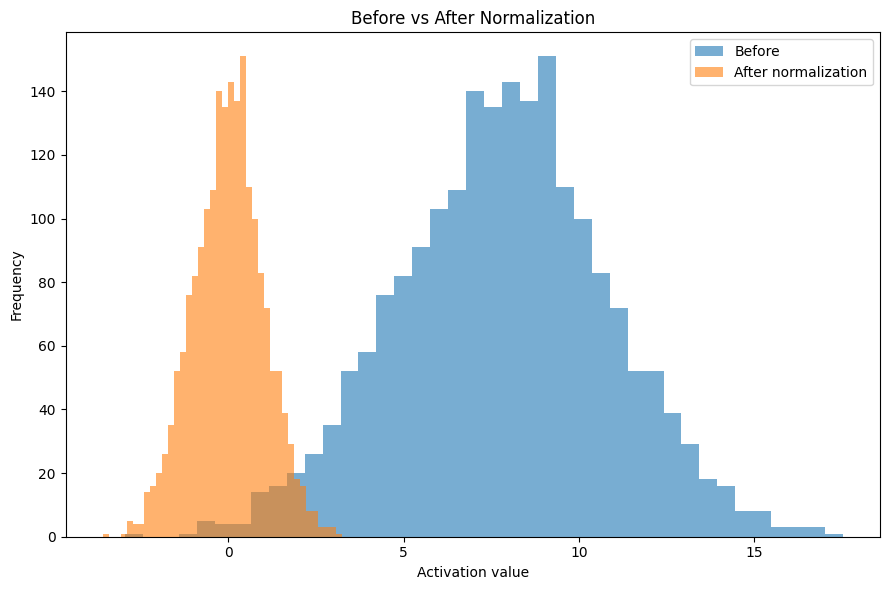

In [4]:
rng=np.random.default_rng(42)

values=rng.normal(loc=8,scale=3,size=2000)
normalized=(values-values.mean())/values.std()

plt.figure(figsize=(9,6))
plt.hist(values,bins=40,alpha=0.6,label="Before")
plt.hist(normalized,bins=40,alpha=0.6,label="After normalization")
plt.xlabel("Activation value")
plt.ylabel("Frequency")
plt.title("Before vs After Normalization")
plt.legend()
plt.tight_layout()
plt.show()


## 7. BatchNorm is not the only normalization

Other techniques include:

- Layer Normalization
- Group Normalization
- Instance Normalization

BatchNorm depends on batch statistics.

That is one reason **Layer Normalization** became especially important in Transformer architectures.


## Simple takeaway

Batch Normalization helps keep activations at healthier scales during training.

It normalizes using batch statistics, then learns its own scale and shift.

> **BatchNorm does not remove learning — it makes the internal signal easier to optimize.**


## References

- https://arxiv.org/abs/1502.03167
- https://pytorch.org/docs/stable/generated/torch.nn.BatchNorm1d.html
- https://www.tensorflow.org/api_docs/python/tf/keras/layers/BatchNormalization
